# Задание 4.14
## Две корзины и формула Байеса

### Условие:
Две корзины с белыми и чёрными шарами. В первой всего 6 шаров, число белых распределено по биномиальному закону с параметрами $n=3$, $p=0{,}8$. Во второй всего 11 шаров, число белых — биномиальное с $n=4$, $p=0{,}7$. Все шары перекладывают в третью корзину. 1) Какова вероятность $\mathbb P(A)$, что случайно вынутый из третьей корзины шар белый? 2) Найдите $\mathbb P(H|A)$ — вероятность того, что вынутый шар первоначально лежал в первой корзине ($H$), если он белый.

### Решение:
Пусть $K_1\sim\mathrm{Bin}(3,0{,}8)$, $K_2\sim\mathrm{Bin}(4,0{,}7)$ — числа белых шаров в корзинах; $\mathbb EK_1=2{,}4$, $\mathbb EK_2=2{,}8$. В третьей корзине $6+11=17$ шаров, из них $K_1+K_2$ белых. 
**1)** При заданных $K_1,K_2$ вероятность вытащить белый равна $\dfrac{K_1+K_2}{17}$. По формуле полной вероятности (усреднение по $K_1,K_2$):
$$\mathbb P(A)=\frac{\mathbb EK_1+\mathbb EK_2}{17}=\frac{2{,}4+2{,}8}{17}=\frac{5{,}2}{17}=\frac{26}{85}\approx0{,}3059 .$$
**2)** Событие $H\cap A$: шар из первой корзины ($\frac{6}{17}$) и белый (при заданном $K_1$ вероятность $\frac{K_1}{6}$): $\mathbb P(H\cap A)=\frac6{17}\cdot\frac{\mathbb EK_1}{6}=\frac{\mathbb EK_1}{17}=\frac{2{,}4}{17}$. По формуле Байеса (определению условной вероятности)
$$\mathbb P(H|A)=\frac{\mathbb P(H\cap A)}{\mathbb P(A)}=\frac{2{,}4}{5{,}2}=\frac{6}{13}\approx0{,}4615 .$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

### Точное вычисление перебором всех значений $K_1,K_2$ (дроби)

In [2]:
def binom_pmf(n, p):
    p = Fraction(p); return [comb(n, k)*p**k*(1 - p)**(n - k) for k in range(n + 1)]
pm1, pm2 = binom_pmf(3, Fraction(8, 10)), binom_pmf(4, Fraction(7, 10))        # распределения K1 и K2

P_A = sum(pm1[k1]*pm2[k2]*Fraction(k1 + k2, 17) for k1 in range(4) for k2 in range(5))      # полная вероятность
P_HA = sum(pm1[k1]*pm2[k2]*Fraction(6, 17)*Fraction(k1, 6) for k1 in range(4) for k2 in range(5))   # P(H ∩ A)
print('P(A)   =', P_A, '≈', float(P_A));  print('P(H∩A) =', P_HA, '≈', float(P_HA));  print('P(H|A) =', P_HA/P_A, '≈', float(P_HA/P_A))
P_cond = float(P_HA/P_A); P_A = float(P_A)

P(A)   = 26/85 ≈ 0.3058823529411765
P(H∩A) = 12/85 ≈ 0.1411764705882353
P(H|A) = 6/13 ≈ 0.46153846153846156


### Моделирование $N=10^6$ опытов (сначала число белых в каждой корзине, затем случайный шар из 17)

P(A):   точное 0.305882, оценка 0.305475
P(H|A): точное 0.461538, оценка 0.461999


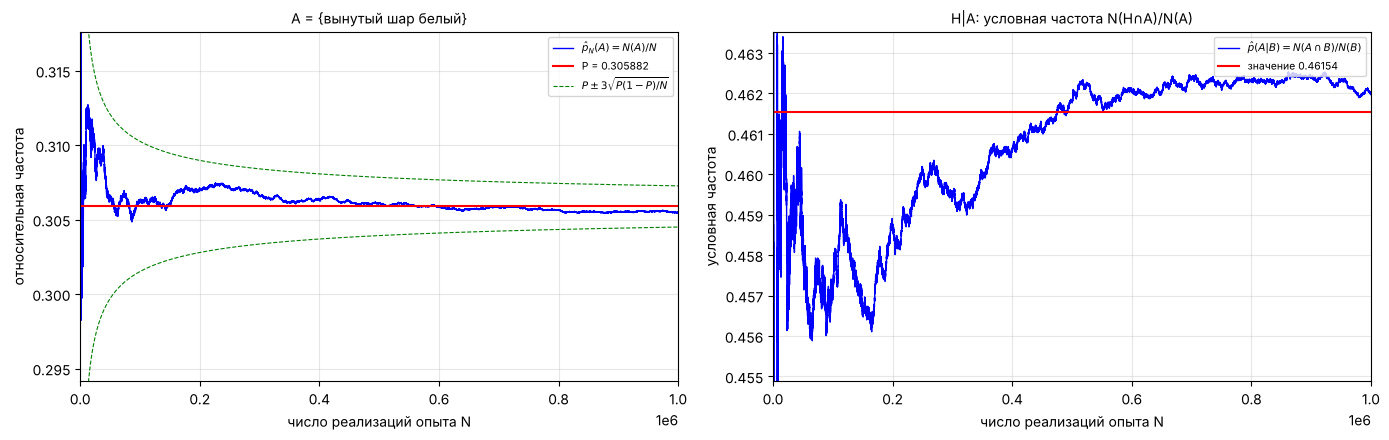

In [3]:
N = 1_000_000
K1, K2 = rng.binomial(3, 0.8, N), rng.binomial(4, 0.7, N)       # числа белых в корзинах 1 и 2
ball = rng.integers(0, 17, N)                                     # номер вынутого шара из 17
from_first = ball < 6                                             # шар из первой корзины (6 шаров)
# в каждой корзине считаем белыми первые K шаров (порядок внутри корзины не важен — шар выбирается равновероятно)
white = np.where(from_first, ball < K1, (ball - 6) < K2)
hit_A, hit_HA = white, white & from_first
print(f'P(A):   точное {P_A:.6f}, оценка {hit_A.mean():.6f}');  print(f'P(H|A): точное {P_cond:.6f}, оценка {hit_HA.sum()/hit_A.sum():.6f}')
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
plot_frequency(axs[0], hit_A, P_A, 'A = {вынутый шар белый}')
plot_conditional(axs[1], hit_HA, hit_A, P_cond, 'H|A: условная частота N(H∩A)/N(A)')
plt.tight_layout(); plt.savefig('task_4_14.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
1) $\mathbb P(A)=\dfrac{26}{85}\approx0{,}3059$; 2) $\mathbb P(H|A)=\dfrac6{13}\approx0{,}4615$.